# 01 · Image audit

Class counts, image statistics, defect areas and the instance-level split — checked before modelling.
Images are **synthetic** steel surfaces with pixel masks (NEU-style).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from visionguard.datasets.dataset import audit, load_dataset

pd.set_option("display.width", 200)
ds = load_dataset()
a = audit(ds)
{k: a[k] for k in ("n_images", "image_shape", "instances", "instance_leakage", "class_counts")}

{'n_images': 1500, 'image_shape': [96, 96], 'instances': 300, 'instance_leakage': 0, 'class_counts': {'normal': 772, 'scratch': 226, 'inclusion': 187, 'crack': 163, 'patch': 152}}

In [2]:
pd.DataFrame(a["by_split"]).T

,crack,inclusion,normal,patch,scratch
test,40,41,146,29,44
train,97,116,471,87,129
validation,26,30,155,36,53


## One example per class with its mask

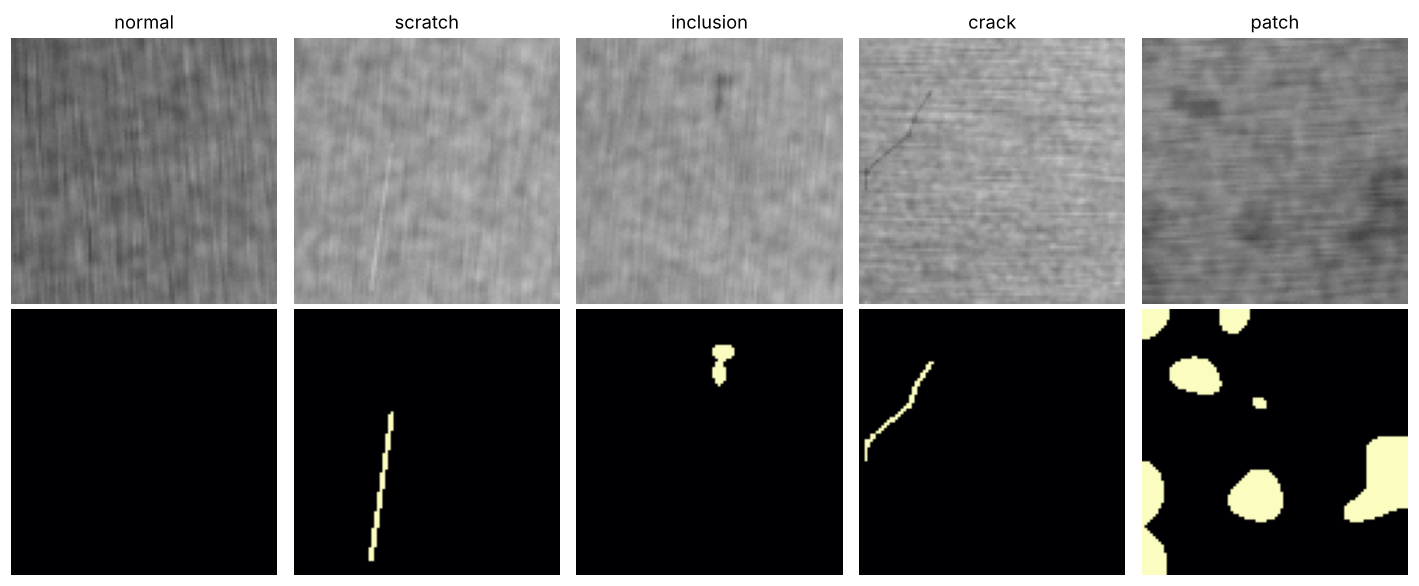

In [3]:
fig, ax = plt.subplots(2, 5, figsize=(13, 5.4))
for c, name in enumerate(["normal", "scratch", "inclusion", "crack", "patch"]):
    i = np.flatnonzero(ds.labels == c)[2]
    ax[0, c].imshow(ds.images[i], cmap="gray", vmin=0, vmax=1)
    ax[0, c].set_title(name)
    ax[1, c].imshow(ds.masks[i], cmap="magma")
for x in ax.ravel():
    x.axis("off")
plt.tight_layout()

## Defect area by class — scratches and cracks are tiny targets

In [4]:
ds.meta[ds.meta.label > 0].groupby("class_name").defect_area.describe().round(4)

,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
crack,163.0,0.0081,0.0029,0.0029,0.0057,0.0077,0.0105,0.0153
inclusion,187.0,0.0146,0.0056,0.0036,0.0103,0.0135,0.0189,0.0285
patch,152.0,0.1699,0.0308,0.1097,0.1456,0.1734,0.1930,0.2322
scratch,226.0,0.0133,0.0031,0.0067,0.0112,0.0129,0.0154,0.0205
